# DRL Trading Agent: TD3

Part B of the Sentiment-Augmented DRL Trading project. Trains **TD3** on a 10-stock
NIFTY portfolio (the same 10 companies most mentioned in the SEntFiN-v1.1 sentiment corpus used
in Part A), with technical indicators + FinBERT-LoRA-scored news sentiment as state features.

**This notebook is self-contained** — upload it to Kaggle, attach `rl_panel.csv` as a dataset
input (built locally via `src/rl/data_pipeline.py`), and run all cells top to bottom.
GPU is **not required** — stable-baselines3's MlpPolicy agents are CPU-bound (the bottleneck is
Python environment-stepping, not matrix math), so a GPU accelerator won't meaningfully speed
this up; Kaggle's CPU session is being used purely for extra wall-clock budget / to free up
the local machine, not for GPU acceleration.

**Pipeline**: baseline (default hyperparameters) → random-search hyperparameter tuning (short
budget per trial, keeps the actual best trial's model — not reinitialized) → continue training
that winning model for a much larger budget, printing progress at regular checkpoints → final
backtest on the held-out test period vs. an equal-weight buy-and-hold benchmark.

Sentiment note: TRAIN/VAL use a bootstrap-resampled sentiment column (real FinBERT-scored values
resampled onto days without real news, so the agent gets varied non-zero sentiment exposure while
learning). TEST keeps only the genuine dated sentiment (real news is sparse — ~59 ticker-days
total in the full panel), which is the only period where a with-sentiment agent's behavior means
anything as an evaluation.

In [1]:
!pip install -q stable-baselines3 gymnasium pandas_ta mlflow

In [2]:
import os
import time
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

import mlflow
from stable_baselines3 import PPO, A2C, DDPG, SAC, TD3
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.noise import NormalActionNoise

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)

AGENT_CLASSES = {"PPO": PPO, "A2C": A2C, "DDPG": DDPG, "SAC": SAC, "TD3": TD3}

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ══════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════
TICKERS = ["INFY.NS", "RELIANCE.NS", "TCS.NS", "SBIN.NS", "MARUTI.NS",
           "WIPRO.NS", "TMPV.NS", "LT.NS", "ITC.NS", "SUNPHARMA.NS"]
INDICATORS = ["macd", "rsi_14", "cci_20", "adx_14"]

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

INITIAL_CASH = 1_000_000.0
MAX_TRADE_FRACTION = 0.15      # max fraction of portfolio value tradable per asset per step
TRANSACTION_COST_PCT = 0.001   # 10 bps per trade, each side
REWARD_LOG_SCALE = 100.0       # scales daily log-return into a friendlier RL reward magnitude
TURNOVER_PENALTY_COEF = 0.01   # discourages excessive churn (each run's turnover is also reported)

SEED = 42
AGENT_NAME = "TD3"
MODEL_NAME = f"{AGENT_NAME}_sentiment"

SEARCH_TRIALS = 10
SEARCH_TIMESTEPS = 30000
FINAL_TIMESTEPS = 400000
N_CHECKPOINTS = 10

MLFLOW_EXPERIMENT = "DRLTrading"

np.random.seed(SEED)

BASE_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{os.path.join(BASE_DIR, 'mlflow.db')}")

## 1. Load the price + technical-indicator + sentiment panel

In [4]:
def resolve_panel_path() -> str:
    candidates = ["../data/processed/rl_panel.csv", "rl_panel.csv"]
    if os.path.isdir("/kaggle/input"):
        for root, _, files in os.walk("/kaggle/input"):
            for f in files:
                if f == "rl_panel.csv":
                    candidates.insert(0, os.path.join(root, f))
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "rl_panel.csv not found. On Kaggle: Add Data -> upload rl_panel.csv (built locally via "
        "src/rl/data_pipeline.py) as a dataset and attach it. Locally: place it at "
        "data/processed/rl_panel.csv."
    )


panel = pd.read_csv(resolve_panel_path(), parse_dates=["date"])
print(f"Panel: {panel.shape[0]} rows, {panel['ticker'].nunique()} tickers, "
      f"{panel['date'].min().date()} -> {panel['date'].max().date()}")
print(f"Real sentiment coverage: {panel['has_real_sentiment'].sum()} rows "
      f"({panel['has_real_sentiment'].mean()*100:.2f}%)")

Panel: 12130 rows, 10 tickers, 2021-08-30 -> 2026-07-22
Real sentiment coverage: 59 rows (0.49%)


## 2. Train / val / test split (chronological)

In [5]:
dates = np.sort(panel["date"].unique())
n = len(dates)
train_end = dates[int(n * TRAIN_FRAC)]
val_end = dates[int(n * (TRAIN_FRAC + VAL_FRAC))]

train_panel = panel[panel["date"] <= train_end].copy()
val_panel = panel[(panel["date"] > train_end) & (panel["date"] <= val_end)].copy()
test_panel = panel[panel["date"] > val_end].copy()

# TRAIN/VAL: use the bootstrap-resampled sentiment (real values resampled onto days without
# real news) so the agent sees varied, non-zero sentiment while learning. TEST keeps the
# genuine real+0-fill column untouched -- that's the actual held-out evaluation.
if "sentiment_bootstrap" in panel.columns:
    train_panel["sentiment"] = train_panel["sentiment_bootstrap"]
    val_panel["sentiment"] = val_panel["sentiment_bootstrap"]

print(f"train: {train_panel['date'].nunique()} days ({train_panel['date'].min().date()} -> {train_panel['date'].max().date()})")
print(f"val:   {val_panel['date'].nunique()} days ({val_panel['date'].min().date()} -> {val_panel['date'].max().date()})")
print(f"test:  {test_panel['date'].nunique()} days ({test_panel['date'].min().date()} -> {test_panel['date'].max().date()})")

train: 850 days (2021-08-30 -> 2025-02-03)
val:   182 days (2025-02-04 -> 2025-10-30)
test:  181 days (2025-10-31 -> 2026-07-22)


## 3. Trading environment

Multi-asset portfolio env. State = cash + holdings + prices + technical indicators (+ sentiment)
per asset. Action = continuous vector in [-1, 1] per asset.

Two design choices worth flagging (fixed after diagnosing issues in an earlier, simpler version):
- **Dollar-consistent trade sizing**: `action[i]` maps to a *fraction of portfolio value* to
  trade in asset `i`, not a flat share count — a flat share-count rule means the same action
  value implies wildly different dollar exposure for a ₹400 stock (ITC) vs. a ₹11,000+ stock
  (MARUTI), which made it harder for one network to learn a consistent policy across assets.
- **Log-return reward with a turnover penalty**: raw currency-delta reward isn't scale-invariant
  as the portfolio grows/shrinks; log-return is. The turnover penalty directly discourages
  excessive churn (an earlier version was trading on 90%+ of days and bleeding real money to
  transaction costs regardless of whether the trades were good calls).

In [6]:
class PortfolioTradingEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, panel_split: pd.DataFrame, tickers=TICKERS, use_sentiment: bool = True,
                 initial_cash: float = INITIAL_CASH, max_trade_frac: float = MAX_TRADE_FRACTION,
                 transaction_cost_pct: float = TRANSACTION_COST_PCT,
                 turnover_penalty_coef: float = TURNOVER_PENALTY_COEF,
                 reward_log_scale: float = REWARD_LOG_SCALE):
        super().__init__()
        self.tickers = list(tickers)
        self.n_assets = len(self.tickers)
        self.use_sentiment = use_sentiment
        self.initial_cash = initial_cash
        self.max_trade_frac = max_trade_frac
        self.transaction_cost_pct = transaction_cost_pct
        self.turnover_penalty_coef = turnover_penalty_coef
        self.reward_log_scale = reward_log_scale

        self.indicator_cols = list(INDICATORS) + (["sentiment"] if use_sentiment else [])

        self.close = panel_split.pivot(index="date", columns="ticker", values="close")[self.tickers]
        self.indicators = {
            col: panel_split.pivot(index="date", columns="ticker", values=col)[self.tickers]
            for col in self.indicator_cols
        }
        self.dates = self.close.index.sort_values()
        self.n_steps = len(self.dates) - 1

        n_features_per_asset = 2 + len(self.indicator_cols)
        obs_dim = 1 + n_features_per_asset * self.n_assets
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32)
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(self.n_assets,), dtype=np.float32)

        self.reset()

    def _get_prices(self, t):
        return self.close.iloc[t].to_numpy(dtype=np.float32)

    def _get_obs(self, t):
        prices = self._get_prices(t)
        parts = [np.array([self.cash], dtype=np.float32), self.holdings.astype(np.float32), prices]
        for col in self.indicator_cols:
            parts.append(self.indicators[col].iloc[t].to_numpy(dtype=np.float32))
        obs = np.concatenate(parts)
        return np.nan_to_num(obs, nan=0.0, posinf=0.0, neginf=0.0)

    def _portfolio_value(self, t):
        return float(self.cash + np.dot(self.holdings, self._get_prices(t)))

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t = 0
        self.cash = self.initial_cash
        self.holdings = np.zeros(self.n_assets, dtype=np.float64)
        self.portfolio_value_history = [self._portfolio_value(self.t)]
        self.total_shares_traded = 0.0
        self.total_transaction_cost = 0.0
        self.n_trade_days = 0
        return self._get_obs(self.t), {}

    def step(self, action):
        action = np.clip(action, -1.0, 1.0)
        prices = self._get_prices(self.t)
        portfolio_value = self._portfolio_value(self.t)

        target_dollar_trade = action * self.max_trade_frac * portfolio_value
        trade_shares = np.where(prices > 0, target_dollar_trade / np.maximum(prices, 1e-9), 0.0)
        trade_shares = np.round(trade_shares)

        day_shares_traded = 0.0
        day_transaction_cost = 0.0
        day_dollar_traded = 0.0

        for i in np.argsort(trade_shares):   # sells (negative) first, frees up cash for buys
            shares = trade_shares[i]
            price = prices[i]
            if price <= 0 or np.isnan(price):
                continue
            if shares < 0:
                sell_shares = min(-shares, self.holdings[i])
                proceeds = sell_shares * price * (1 - self.transaction_cost_pct)
                self.cash += proceeds
                self.holdings[i] -= sell_shares
                day_shares_traded += sell_shares
                day_transaction_cost += sell_shares * price * self.transaction_cost_pct
                day_dollar_traded += sell_shares * price
            elif shares > 0:
                cost_per_share = price * (1 + self.transaction_cost_pct)
                affordable = np.floor(self.cash / cost_per_share) if cost_per_share > 0 else 0
                buy_shares = min(shares, affordable)
                self.cash -= buy_shares * cost_per_share
                self.holdings[i] += buy_shares
                day_shares_traded += buy_shares
                day_transaction_cost += buy_shares * price * self.transaction_cost_pct
                day_dollar_traded += buy_shares * price

        self.total_shares_traded += day_shares_traded
        self.total_transaction_cost += day_transaction_cost
        if day_shares_traded > 0:
            self.n_trade_days += 1

        prev_value = self._portfolio_value(self.t)
        self.t += 1
        terminated = self.t >= self.n_steps
        new_value = self._portfolio_value(min(self.t, self.n_steps))

        log_return = np.log(max(new_value, 1e-9) / max(prev_value, 1e-9))
        turnover_frac = day_dollar_traded / max(prev_value, 1e-9)
        reward = log_return * self.reward_log_scale - self.turnover_penalty_coef * turnover_frac

        self.portfolio_value_history.append(new_value)
        obs = self._get_obs(min(self.t, self.n_steps))
        info = {
            "portfolio_value": new_value,
            "date": str(self.dates[min(self.t, self.n_steps)].date()),
            "day_shares_traded": day_shares_traded,
            "day_transaction_cost": day_transaction_cost,
        }
        if terminated:
            info["total_shares_traded"] = self.total_shares_traded
            info["total_transaction_cost"] = self.total_transaction_cost
            info["n_trade_days"] = self.n_trade_days
            info["n_steps"] = self.n_steps
        return obs, reward, terminated, False, info

## 4. Environment + backtest helpers

In [7]:
def make_env(panel_split: pd.DataFrame, use_sentiment: bool = True, training: bool = True):
    def _init():
        env = PortfolioTradingEnv(panel_split, use_sentiment=use_sentiment)
        return Monitor(env)
    vec_env = DummyVecEnv([_init])
    vec_env = VecNormalize(vec_env, norm_obs=True, norm_reward=training, clip_obs=10.0)
    return vec_env


def backtest(model, panel_split, norm_stats_env, use_sentiment: bool = True):
    """Deterministic rollout using FROZEN normalization stats from norm_stats_env (no further updates)."""
    eval_env = make_env(panel_split, use_sentiment, training=False)
    eval_env.obs_rms = norm_stats_env.obs_rms
    eval_env.training = False
    eval_env.norm_reward = False

    obs = eval_env.reset()
    values, turnover_info = [], {}
    done = False
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, done, info = eval_env.step(action)
        done = bool(done[0])
        values.append(info[0]["portfolio_value"])
        if "total_shares_traded" in info[0]:
            turnover_info = info[0]

    values = np.array(values)
    returns = np.diff(values) / values[:-1]
    cumulative_return_pct = (values[-1] / INITIAL_CASH - 1) * 100
    sharpe = (returns.mean() / (returns.std() + 1e-9)) * np.sqrt(252) if len(returns) > 1 else 0.0
    running_max = np.maximum.accumulate(values)
    max_drawdown_pct = ((values - running_max) / running_max).min() * 100

    n_steps = turnover_info.get("n_steps", len(values))
    diagnostics = {
        "avg_daily_shares_traded": turnover_info.get("total_shares_traded", 0.0) / max(n_steps, 1),
        "pct_days_traded": turnover_info.get("n_trade_days", 0) / max(n_steps, 1) * 100,
        "total_transaction_cost": turnover_info.get("total_transaction_cost", 0.0),
    }
    return {"cumulative_return_pct": cumulative_return_pct, "sharpe": sharpe,
            "max_drawdown_pct": max_drawdown_pct, "values": values, **diagnostics}


def buy_and_hold(panel_split, tickers=TICKERS, initial_cash=INITIAL_CASH):
    close = panel_split.pivot(index="date", columns="ticker", values="close")[tickers].sort_index()
    shares = (initial_cash / len(tickers)) / close.iloc[0]
    return (close * shares).sum(axis=1).to_numpy()

## 5. Environment sanity check

In [8]:
_env = PortfolioTradingEnv(train_panel)
print(f"obs_dim={_env.observation_space.shape} action_dim={_env.action_space.shape} n_steps={_env.n_steps}")
_obs, _ = _env.reset()
for _ in range(5):
    _obs, _r, _term, _trunc, _info = _env.step(_env.action_space.sample())
print("Random-policy smoke test ok. Sample portfolio_value:", _info["portfolio_value"])
del _env

obs_dim=(71,) action_dim=(10,) n_steps=849
Random-policy smoke test ok. Sample portfolio_value: 1021974.8855081788


## 6. Agent builder

In [9]:
def build_agent(env, params: dict, seed: int = SEED):
    kwargs = dict(policy="MlpPolicy", env=env, seed=seed, verbose=0)
    params = dict(params)
    action_noise_sigma = params.pop("action_noise_sigma", 0.1)
    n_actions = env.action_space.shape[-1]
    kwargs["action_noise"] = NormalActionNoise(mean=np.zeros(n_actions), sigma=action_noise_sigma * np.ones(n_actions))
    kwargs.update(params)
    return TD3(**kwargs)

## 7. Baseline run (default hyperparameters)

One-shot training with sensible defaults for TD3, evaluated on val — the reference
point the tuned model needs to beat.

In [10]:
DEFAULT_PARAMS = {
    "learning_rate": 0.001,
    "buffer_size": 200000,
    "batch_size": 100,
    "tau": 0.005,
    "gamma": 0.99,
    "policy_delay": 2,
    "action_noise_sigma": 0.1
}

mlflow.set_experiment(MLFLOW_EXPERIMENT)

train_env = make_env(train_panel)
baseline_model = build_agent(train_env, DEFAULT_PARAMS)

start = time.time()
baseline_model.learn(total_timesteps=SEARCH_TIMESTEPS, progress_bar=False)
baseline_train_time = time.time() - start

baseline_metrics = backtest(baseline_model, val_panel, train_env)
print(f"Baseline {MODEL_NAME}: train_time={baseline_train_time:.1f}s | "
      f"val_return={baseline_metrics['cumulative_return_pct']:.2f}% | "
      f"val_sharpe={baseline_metrics['sharpe']:.3f} | "
      f"pct_days_traded={baseline_metrics['pct_days_traded']:.1f}% | "
      f"total_txn_cost=Rs.{baseline_metrics['total_transaction_cost']:.0f}")

with mlflow.start_run(run_name=f"{MODEL_NAME}_baseline"):
    mlflow.log_params({"agent": AGENT_NAME, **DEFAULT_PARAMS})
    mlflow.log_metric("train_time_seconds", round(baseline_train_time, 2))
    mlflow.log_metric("val_cumulative_return_pct", baseline_metrics["cumulative_return_pct"])
    mlflow.log_metric("val_sharpe", baseline_metrics["sharpe"])

Baseline TD3_sentiment: train_time=424.6s | val_return=-5.34% | val_sharpe=-0.252 | pct_days_traded=34.8% | total_txn_cost=Rs.11135


## 8. Hyperparameter tuning (random search)

Random search over TD3's hyperparameters: each of `SEARCH_TRIALS` trials trains a
**fresh** agent for the short `SEARCH_TIMESTEPS` budget, and we keep the actual trained model
object of whichever trial gets the best val Sharpe — not just its config — so Section 9 can
keep training that exact model instead of reinitializing and losing what it already learned.

In [11]:
SEARCH_SPACE = {
    "learning_rate": [
        0.0001,
        0.0003,
        0.001,
        0.003
    ],
    "batch_size": [
        64,
        100,
        256
    ],
    "tau": [
        0.001,
        0.005,
        0.01
    ],
    "gamma": [
        0.95,
        0.99,
        0.995
    ],
    "policy_delay": [
        1,
        2,
        3
    ],
    "action_noise_sigma": [
        0.05,
        0.1,
        0.2,
        0.3
    ]
}


def sample_config(rng: np.random.RandomState) -> dict:
    return {k: rng.choice(v) for k, v in SEARCH_SPACE.items()}


def run_trial(config: dict, timesteps: int):
    tl = make_env(train_panel)
    model = build_agent(tl, config)
    start = time.time()
    model.learn(total_timesteps=timesteps, progress_bar=False)
    train_time = time.time() - start
    metrics = backtest(model, val_panel, tl)
    return {"model": model, "train_env": tl, "config": config,
            "val_sharpe": metrics["sharpe"], "val_return": metrics["cumulative_return_pct"],
            "train_time": train_time}


rng = np.random.RandomState(SEED)
trial_results = []
best_overall = None

print(f"Running {SEARCH_TRIALS} random-search trials ({SEARCH_TIMESTEPS} timesteps each)...\n")
for trial_idx in range(1, SEARCH_TRIALS + 1):
    config = sample_config(rng)
    result = run_trial(config, SEARCH_TIMESTEPS)

    print(f"Trial {trial_idx}/{SEARCH_TRIALS} | config={config} | "
          f"val_return={result['val_return']:.2f}% | val_sharpe={result['val_sharpe']:.3f} | "
          f"time={result['train_time']:.1f}s")

    trial_results.append({"trial": trial_idx, **{k: v for k, v in result["config"].items()},
                           "val_return_pct": result["val_return"], "val_sharpe": result["val_sharpe"],
                           "train_time": result["train_time"]})

    if best_overall is None or result["val_sharpe"] > best_overall["val_sharpe"]:
        if best_overall is not None:
            del best_overall["model"], best_overall["train_env"]
        best_overall = result
    else:
        del result["model"], result["train_env"]

leaderboard_df = pd.DataFrame(trial_results).sort_values("val_sharpe", ascending=False).reset_index(drop=True)
print("\n" + "=" * 70)
print("RANDOM SEARCH LEADERBOARD (by val Sharpe)")
print("=" * 70)
print(leaderboard_df.to_string(index=False))

tuned_config = best_overall["config"]
tuned_model = best_overall["model"]
tuned_train_env = best_overall["train_env"]
print(f"\nBest config: {tuned_config}")
print(f"Best val Sharpe (search stage): {best_overall['val_sharpe']:.3f}")

Running 10 random-search trials (30000 timesteps each)...



Trial 1/10 | config={'learning_rate': np.float64(0.001), 'batch_size': np.int64(64), 'tau': np.float64(0.01), 'gamma': np.float64(0.995), 'policy_delay': np.int64(1), 'action_noise_sigma': np.float64(0.05)} | val_return=-15.28% | val_sharpe=-1.061 | time=450.2s


Trial 2/10 | config={'learning_rate': np.float64(0.001), 'batch_size': np.int64(100), 'tau': np.float64(0.01), 'gamma': np.float64(0.995), 'policy_delay': np.int64(3), 'action_noise_sigma': np.float64(0.2)} | val_return=-18.65% | val_sharpe=-1.414 | time=358.3s


Trial 3/10 | config={'learning_rate': np.float64(0.003), 'batch_size': np.int64(64), 'tau': np.float64(0.01), 'gamma': np.float64(0.99), 'policy_delay': np.int64(1), 'action_noise_sigma': np.float64(0.1)} | val_return=12.11% | val_sharpe=1.302 | time=372.1s


Trial 4/10 | config={'learning_rate': np.float64(0.003), 'batch_size': np.int64(100), 'tau': np.float64(0.005), 'gamma': np.float64(0.99), 'policy_delay': np.int64(1), 'action_noise_sigma': np.float64(0.05)} | val_return=14.46% | val_sharpe=1.276 | time=440.5s


...

Trial 6/10 | config={'learning_rate': np.float64(0.001), 'batch_size': np.int64(256), 'tau': np.float64(0.01), 'gamma': np.float64(0.99), 'policy_delay': np.int64(3), 'action_noise_sigma': np.float64(0.1)} | val_return=1.23% | val_sharpe=0.211 | time=454.1s


Trial 7/10 | config={'learning_rate': np.float64(0.0003), 'batch_size': np.int64(256), 'tau': np.float64(0.005), 'gamma': np.float64(0.995), 'policy_delay': np.int64(3), 'action_noise_sigma': np.float64(0.3)} | val_return=-6.45% | val_sharpe=-0.328 | time=482.1s


Trial 8/10 | config={'learning_rate': np.float64(0.003), 'batch_size': np.int64(64), 'tau': np.float64(0.01), 'gamma': np.float64(0.95), 'policy_delay': np.int64(3), 'action_noise_sigma': np.float64(0.2)} | val_return=6.70% | val_sharpe=0.850 | time=238.5s


Trial 9/10 | config={'learning_rate': np.float64(0.0001), 'batch_size': np.int64(64), 'tau': np.float64(0.01), 'gamma': np.float64(0.99), 'policy_delay': np.int64(1), 'action_noise_sigma': np.float64(0.3)} | val_return=-11.74% | val_sharpe=-0.714 | time=261.2s


Trial 10/10 | config={'learning_rate': np.float64(0.0003), 'batch_size': np.int64(100), 'tau': np.float64(0.005), 'gamma': np.float64(0.95), 'policy_delay': np.int64(2), 'action_noise_sigma': np.float64(0.05)} | val_return=-25.65% | val_sharpe=-1.975 | time=264.9s

RANDOM SEARCH LEADERBOARD (by val Sharpe)
 trial  learning_rate  batch_size   tau  gamma  policy_delay  action_noise_sigma  val_return_pct  val_sharpe  train_time
     3         0.0030          64 0.010  0.990             1                0.10       12.112913    1.302281  372.114544
     4         0.0030         100 0.005  0.990             1                0.05       14.460124    1.275742  440.514741
     8         0.0030          64 0.010  0.950             3                0.20        6.697188    0.850075  238.518301
     6         0.0010         256 0.010  0.990             3                0.10        1.228312    0.210932  454.131844
     7         0.0003         256 0.005  0.995             3                0.30       

## 9. Continue training the winning model to the full budget

We do **not** reinitialize the winning model — it already learned something during the search.
We continue training that exact model object in `N_CHECKPOINTS` chunks totalling `FINAL_TIMESTEPS`
additional steps, backtesting on val after every chunk so progress is visible throughout (RL
doesn't have "epochs" the same way supervised learning does, so a checkpoint here is the
closest equivalent — same spirit as the per-epoch tables used for the Part A models).

Continuing training for 400000 more timesteps (10 checkpoints of 40000 each)...

Checkpoint |  timesteps |  val_return% | val_sharpe | pct_days_traded
----------------------------------------------------------------------


         1 |      40000 |       12.11% |      1.302 |            2.2%


         2 |      80000 |       12.11% |      1.302 |            2.2%


         3 |     120000 |       12.11% |      1.302 |            2.2%


         4 |     160000 |       12.11% |      1.302 |            2.2%


...

         6 |     240000 |       13.49% |      1.378 |            2.2%


         7 |     280000 |       15.64% |      1.467 |            3.3%


         8 |     320000 |        2.54% |      0.357 |            1.7%


         9 |     360000 |       15.08% |      1.437 |            3.3%


        10 |     400000 |        2.54% |      0.357 |            1.7%


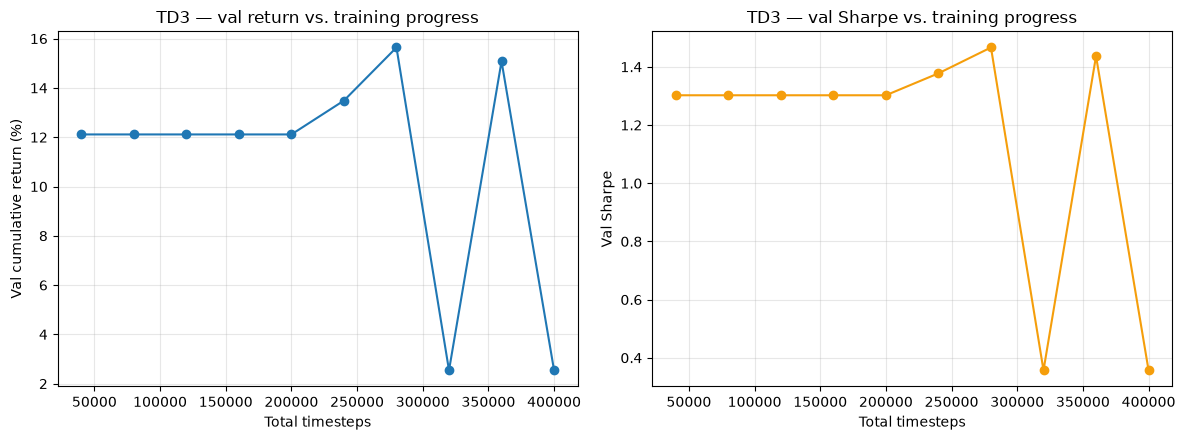


Total continued-training time: 2885.8s


In [12]:
checkpoint_timesteps = FINAL_TIMESTEPS // N_CHECKPOINTS
history = []

print(f"Continuing training for {FINAL_TIMESTEPS} more timesteps ({N_CHECKPOINTS} checkpoints of {checkpoint_timesteps} each)...\n")
print(f"{'Checkpoint':>10} | {'timesteps':>10} | {'val_return%':>12} | {'val_sharpe':>10} | {'pct_days_traded':>15}")
print("-" * 70)

start = time.time()
for ckpt in range(1, N_CHECKPOINTS + 1):
    tuned_model.learn(total_timesteps=checkpoint_timesteps, reset_num_timesteps=False, progress_bar=False)
    metrics = backtest(tuned_model, val_panel, tuned_train_env)
    history.append({"checkpoint": ckpt, "timesteps": ckpt * checkpoint_timesteps,
                     "val_return_pct": metrics["cumulative_return_pct"], "val_sharpe": metrics["sharpe"],
                     "pct_days_traded": metrics["pct_days_traded"]})
    print(f"{ckpt:>10} | {ckpt * checkpoint_timesteps:>10} | {metrics['cumulative_return_pct']:>11.2f}% | "
          f"{metrics['sharpe']:>10.3f} | {metrics['pct_days_traded']:>14.1f}%")

tuned_train_time = time.time() - start
history_df = pd.DataFrame(history)
history_path = os.path.join(RESULTS_DIR, f"history_{MODEL_NAME}.csv")
history_df.to_csv(history_path, index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history_df["timesteps"], history_df["val_return_pct"], marker="o")
axes[0].set_title(f"{AGENT_NAME} — val return vs. training progress")
axes[0].set_xlabel("Total timesteps"); axes[0].set_ylabel("Val cumulative return (%)"); axes[0].grid(alpha=0.3)
axes[1].plot(history_df["timesteps"], history_df["val_sharpe"], marker="o", color="#f59e0b")
axes[1].set_title(f"{AGENT_NAME} — val Sharpe vs. training progress")
axes[1].set_xlabel("Total timesteps"); axes[1].set_ylabel("Val Sharpe"); axes[1].grid(alpha=0.3)
plt.tight_layout()
curve_path = os.path.join(RESULTS_DIR, f"training_curve_{MODEL_NAME}.png")
plt.savefig(curve_path, dpi=120, bbox_inches="tight")
plt.show()

print(f"\nTotal continued-training time: {tuned_train_time:.1f}s")

## 10. Final evaluation on the held-out TEST period (vs. buy-and-hold)

TEST PERIOD — TD3_sentiment vs. Buy&Hold
      variant  return_pct    sharpe  max_drawdown_pct
TD3_sentiment  -22.883880 -1.999490        -26.772088
     Buy&Hold  -13.381143 -1.256201        -18.346735

Turnover: avg_daily_shares_traded=5.5 | pct_days_traded=1.7% | total_txn_cost=Rs.999

>>> Did NOT beat buy-and-hold on either metric.


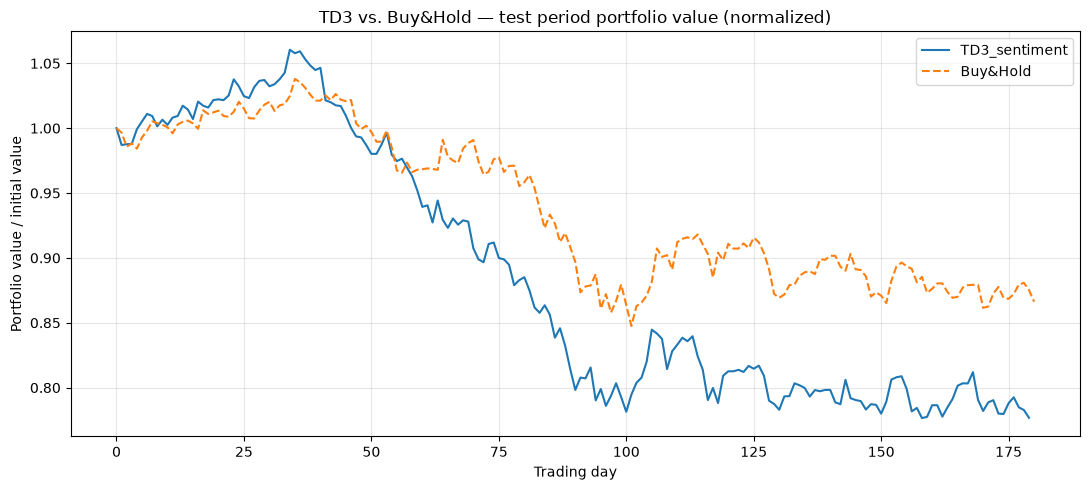

In [13]:
test_metrics = backtest(tuned_model, test_panel, tuned_train_env)
bh_values = buy_and_hold(test_panel)
bh_returns = np.diff(bh_values) / bh_values[:-1]
bh_sharpe = (bh_returns.mean() / (bh_returns.std() + 1e-9)) * np.sqrt(252)
bh_running_max = np.maximum.accumulate(bh_values)
bh_max_dd = ((bh_values - bh_running_max) / bh_running_max).min() * 100
bh_return = (bh_values[-1] / bh_values[0] - 1) * 100

comparison_df = pd.DataFrame([
    {"variant": MODEL_NAME, "return_pct": test_metrics["cumulative_return_pct"],
     "sharpe": test_metrics["sharpe"], "max_drawdown_pct": test_metrics["max_drawdown_pct"]},
    {"variant": "Buy&Hold", "return_pct": bh_return, "sharpe": bh_sharpe, "max_drawdown_pct": bh_max_dd},
])
print("=" * 65)
print(f"TEST PERIOD — {MODEL_NAME} vs. Buy&Hold")
print("=" * 65)
print(comparison_df.to_string(index=False))
print(f"\nTurnover: avg_daily_shares_traded={test_metrics['avg_daily_shares_traded']:.1f} | "
      f"pct_days_traded={test_metrics['pct_days_traded']:.1f}% | "
      f"total_txn_cost=Rs.{test_metrics['total_transaction_cost']:.0f}")

beat_return = test_metrics["cumulative_return_pct"] > bh_return
beat_sharpe = test_metrics["sharpe"] > bh_sharpe
print(f"\n{'='*65}")
if beat_return and beat_sharpe:
    print(">>> BEAT BUY-AND-HOLD on both return and Sharpe.")
elif beat_sharpe:
    print(">>> Better risk-adjusted (Sharpe) than buy-and-hold, but lower raw return.")
elif beat_return:
    print(">>> Higher raw return than buy-and-hold, but worse risk-adjusted (Sharpe) -- a wilder ride, not necessarily better.")
else:
    print(">>> Did NOT beat buy-and-hold on either metric.")
print(f"{'='*65}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(test_metrics["values"] / test_metrics["values"][0], label=MODEL_NAME)
ax.plot(bh_values / bh_values[0], "--", label="Buy&Hold")
ax.set_title(f"{AGENT_NAME} vs. Buy&Hold — test period portfolio value (normalized)")
ax.set_xlabel("Trading day"); ax.set_ylabel("Portfolio value / initial value")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
test_curve_path = os.path.join(RESULTS_DIR, f"test_curve_{MODEL_NAME}.png")
plt.savefig(test_curve_path, dpi=120, bbox_inches="tight")
plt.show()

with mlflow.start_run(run_name=f"{MODEL_NAME}_tuned"):
    mlflow.log_params({"agent": AGENT_NAME, **{k: v for k, v in tuned_config.items()}})
    mlflow.log_metric("test_return_pct", test_metrics["cumulative_return_pct"])
    mlflow.log_metric("test_sharpe", test_metrics["sharpe"])
    mlflow.log_metric("test_max_drawdown_pct", test_metrics["max_drawdown_pct"])
    mlflow.log_metric("bh_return_pct", bh_return)
    mlflow.log_metric("bh_sharpe", bh_sharpe)
    mlflow.log_artifact(history_path)
    mlflow.log_artifact(curve_path)
    mlflow.log_artifact(test_curve_path)

## 11. Save model for local download

In [14]:
model_path = os.path.join(MODELS_DIR, f"{MODEL_NAME}.zip")
norm_path = os.path.join(MODELS_DIR, f"{MODEL_NAME}_vecnormalize.pkl")
tuned_model.save(model_path)
tuned_train_env.save(norm_path)

print(f"Saved model to: {model_path}")
print(f"Saved normalization stats to: {norm_path}")
print(f"\nDownload these from the Kaggle notebook's Output tab before your session ends:")
print(f"  - {MODELS_DIR}/  (trained model + VecNormalize stats)")
print(f"  - {RESULTS_DIR}/  (training curves, test comparison plot)")
print(f"  - {os.path.join(BASE_DIR, 'mlflow.db')}  (all MLflow metrics/params)")

Saved model to: ./saved_models/TD3_sentiment.zip
Saved normalization stats to: ./saved_models/TD3_sentiment_vecnormalize.pkl

Download these from the Kaggle notebook's Output tab before your session ends:
  - ./saved_models/  (trained model + VecNormalize stats)
  - ./results/  (training curves, test comparison plot)
  - ./mlflow.db  (all MLflow metrics/params)
